# 6. Wykresy do preprintu

Rysuje wszystkie wykresy preprintu (po angielsku) w **tym samym stylu co wcześniej** – kod rysowania jest przeniesiony z notebooka
`4_analizy_llm_hate_migrant/cross_platform_hate_analysis.ipynb` z gałęzi `gold_herbert` (mapa zmian, H1, uwaga vs ton, przebieg dzienny,
H2, H3, słowa, chmura, cele, autorzy, lajki), z `6_wyniki_koncowe/wyniki_koncowe.ipynb` (złoty standard) i z notebooka `hate_analysis`
(cechy hejtu). Liczby są z analizy na etykietach Gemini (20 wydarzeń).

**Najpierw** odpal notebooki 2–5 (albo `python scripts/final_analysis_gemini.py`) – ten notebook czyta tylko ich wyniki
(bez tekstów komentarzy): `reports/final_gemini/results.json`, `cell_effects.csv`, `decomposition.csv`, `daily.csv`, `cloud_freq.json`
i `reports/gold_gemini_eval/*.csv`.

Wykresy zapisują się w `reports/final_gemini/preprint/` pod nazwami używanymi w `main.tex` preprintu.
Ten sam kod jako skrypt: `python scripts/final_figures_gemini.py`.
Obrazek pipeline'u (`fig_pipeline_en.png`) jest rysowany ręcznie i nie powstaje tutaj.

In [1]:
import sys
from pathlib import Path
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "events.json").exists())
sys.path.insert(0, str(ROOT / "scripts"))
import final_figures_gemini as ff


def show(name, width=900):
    # small preview in the notebook; the full-size figure is in reports/final_gemini/preprint/
    import io
    from PIL import Image as PILImage
    im = PILImage.open(ff.OUT / f"{name}.png").convert("RGB")
    im.thumbnail((width, 10_000))
    buf = io.BytesIO()
    im.quantize(colors=256).save(buf, format="PNG", optimize=True)
    display(Image(data=buf.getvalue()))

### Złoty standard (Rys. 2)

saved fig_gold_en


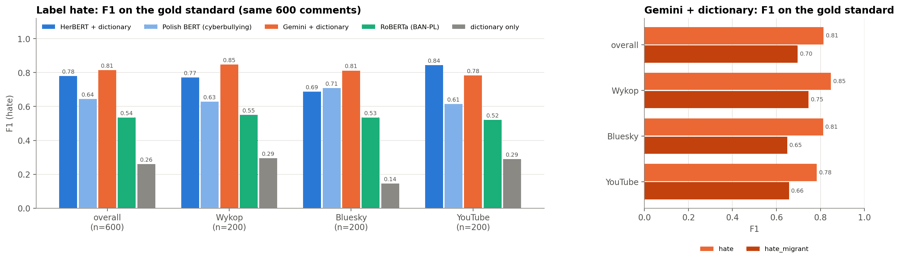

In [2]:
ff.fig_gold()
show("fig_gold_en")

### H1: mapa zmian – OR każdej komórki (Rys. 3)

saved fig_heatmap_en


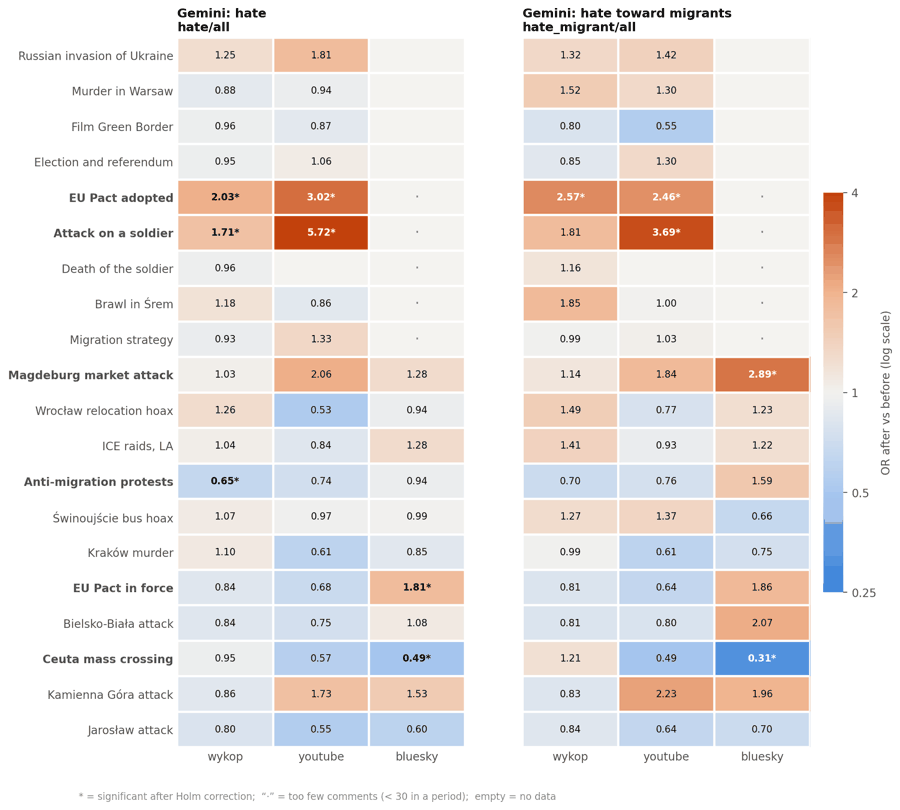

In [3]:
ff.fig_heatmap()
show("fig_heatmap_en")

### H1: wszystkie komórki razem (Rys. 4)

saved fig_pooled_en


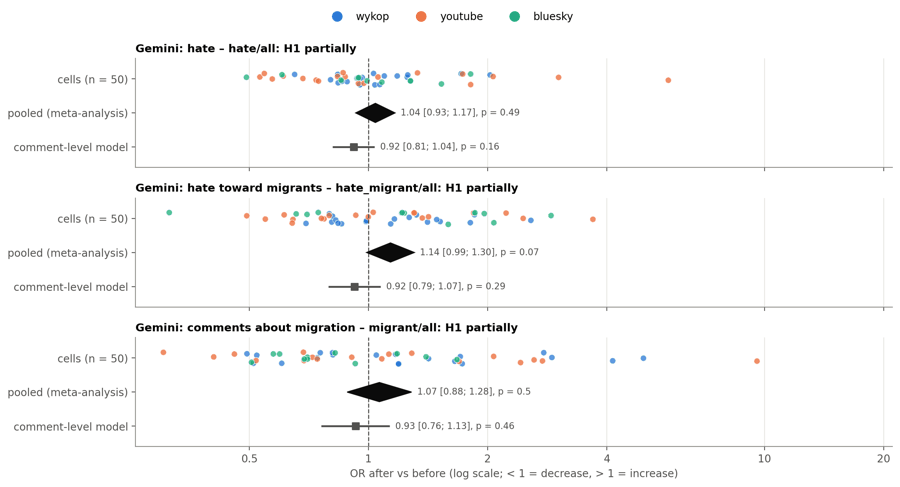

In [4]:
ff.fig_pooled()
show("fig_pooled_en")

### Sprawdzenie HerBERTem (Rys. 5)

saved fig_herbert_en


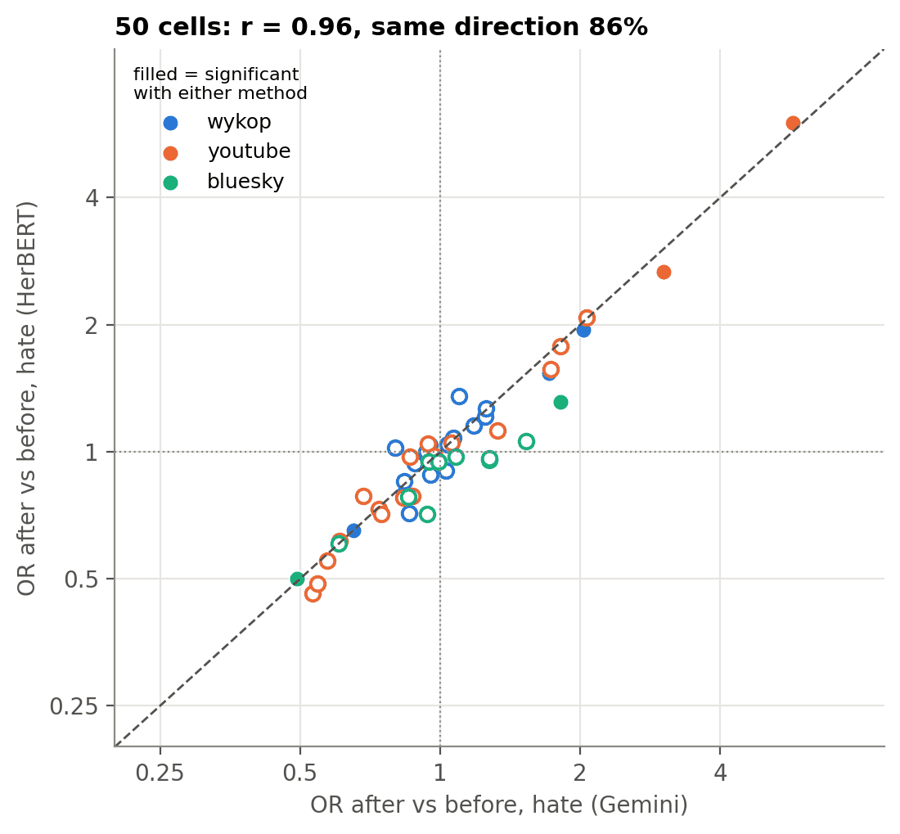

In [5]:
ff.fig_herbert()
show("fig_herbert_en")

### H1: uwaga vs ton (Rys. 6)

saved fig_decomp_en


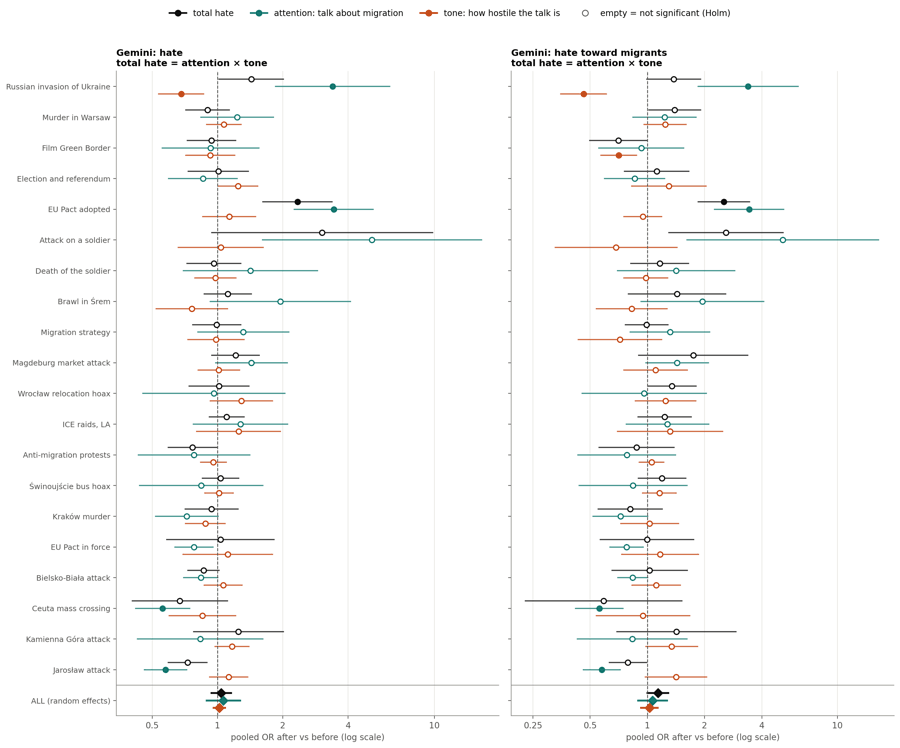

In [6]:
ff.fig_decomp()
show("fig_decomp_en")

### H1: przebieg dzienny – trzy wydarzenia o największej zmianie spośród tych z istotną komórką (Rys. 7)

['2024-04-10_Pakt_Azyl_PE', '2024-05-28_Atak_Zolnierz_Granica', '2024-12-20_Atak_Jarmark_Magdeburg']


saved fig_daily_en


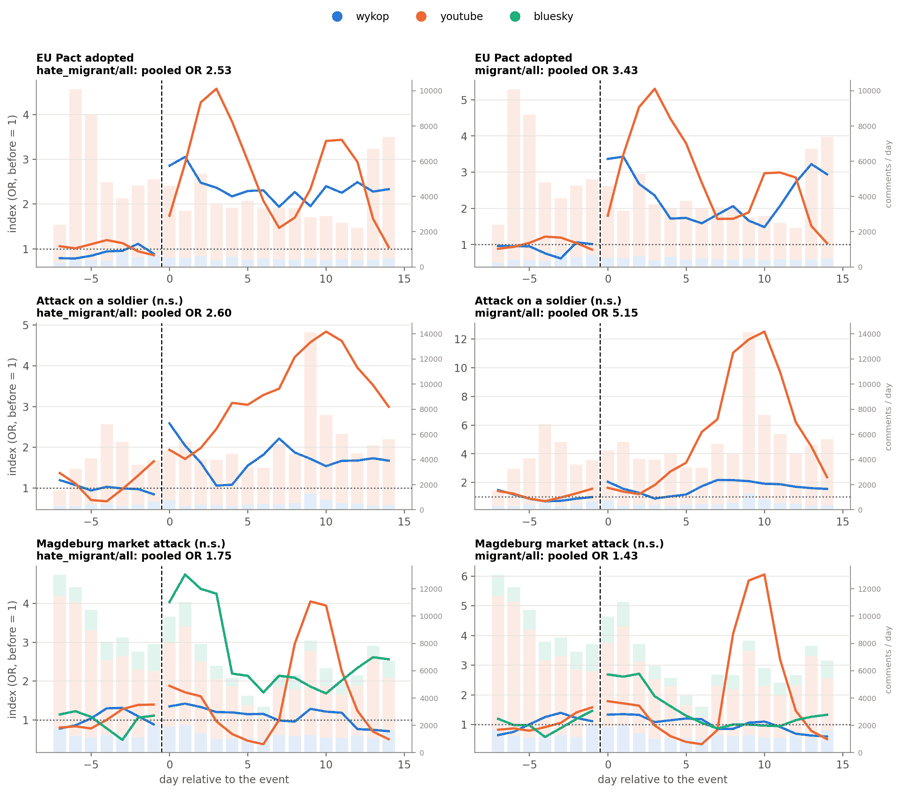

In [7]:
events = ff.top_events(3)
print(events)
ff.fig_daily(events)
show("fig_daily_en")

### H2: typy wydarzeń (Rys. 8)

saved fig_h2_en


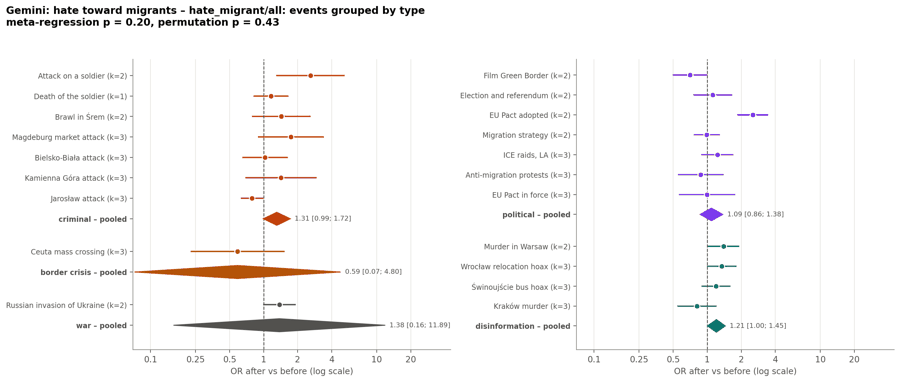

In [8]:
ff.fig_h2("hate_migrant")
show("fig_h2_en")

### H3: platformy (Rys. 9)

saved fig_h3_en


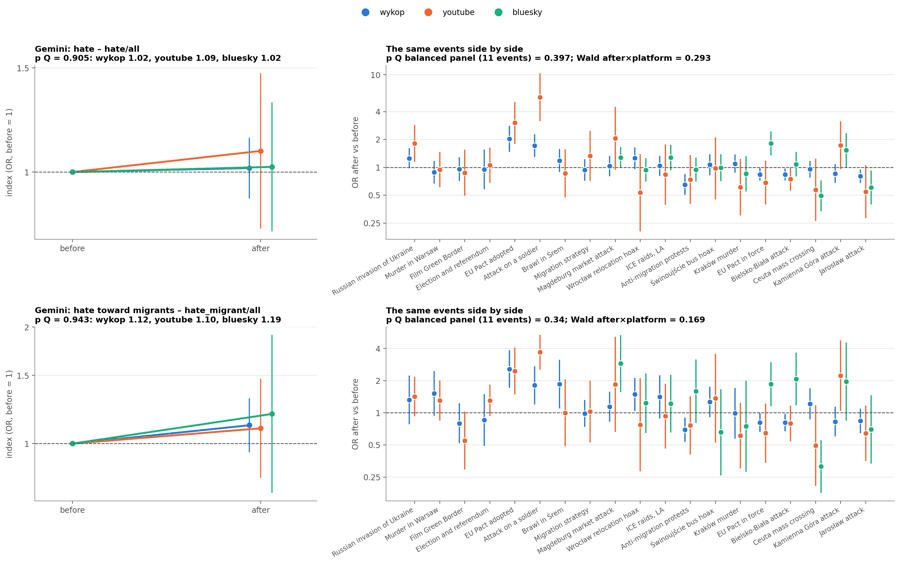

In [9]:
ff.fig_h3()
show("fig_h3_en")

### Q1(a): chmura słów (Rys. 10)

saved fig_cloud_en


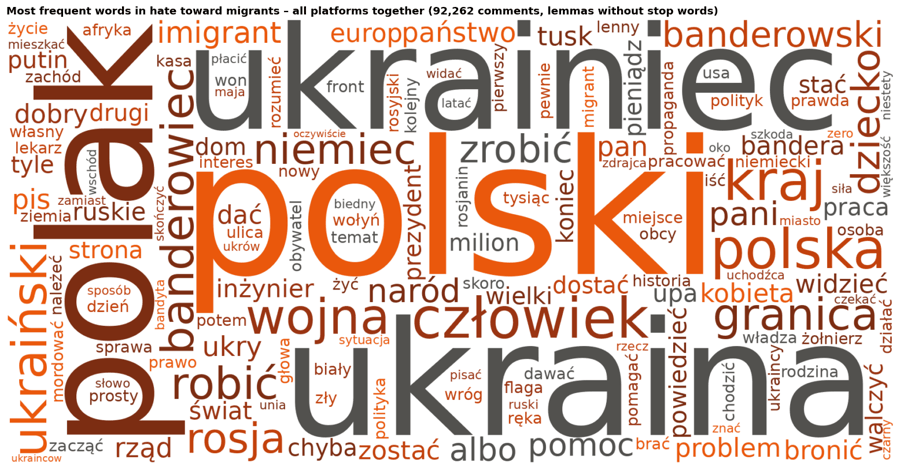

In [10]:
ff.fig_cloud()
show("fig_cloud_en")

### Q1(a): słowa wyróżniające hejt (Rys. 11)

saved fig_words_en


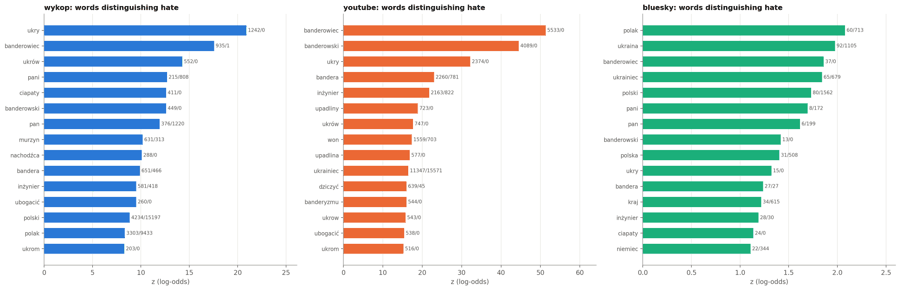

In [11]:
ff.fig_words()
show("fig_words_en")

### Q1(a): kogo atakuje hejt (Rys. 12)

saved fig_targets_en


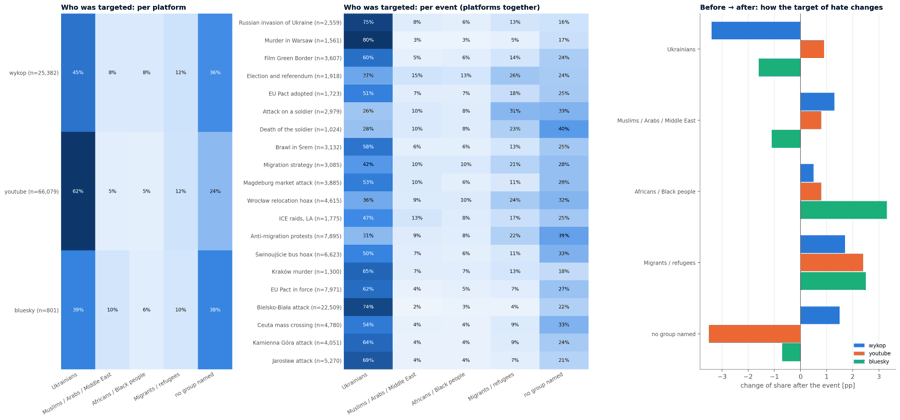

In [12]:
ff.fig_targets()
show("fig_targets_en")

### Q1(a): autorzy i lajki (Rys. 14)

saved fig_authors_en


saved fig_likes_en


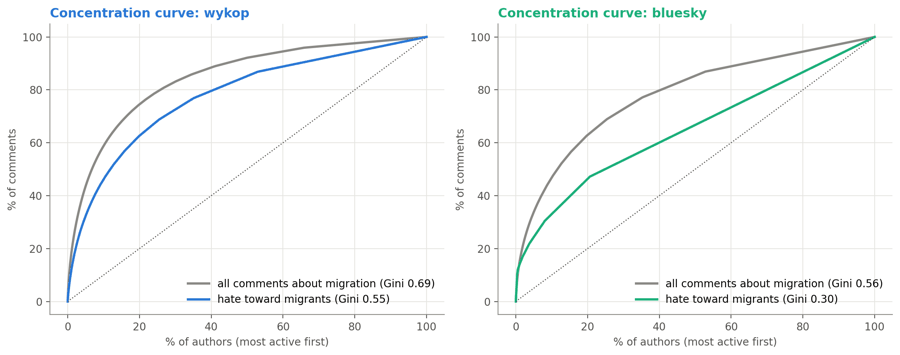

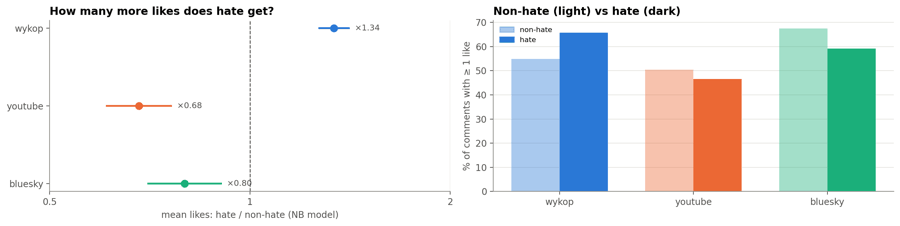

In [13]:
ff.fig_authors()
ff.fig_likes()
show("fig_authors_en")
show("fig_likes_en")

### Q1(b): cechy hejtu (Rys. 13, 15)

saved ha_2_profile
saved ha_4_logit


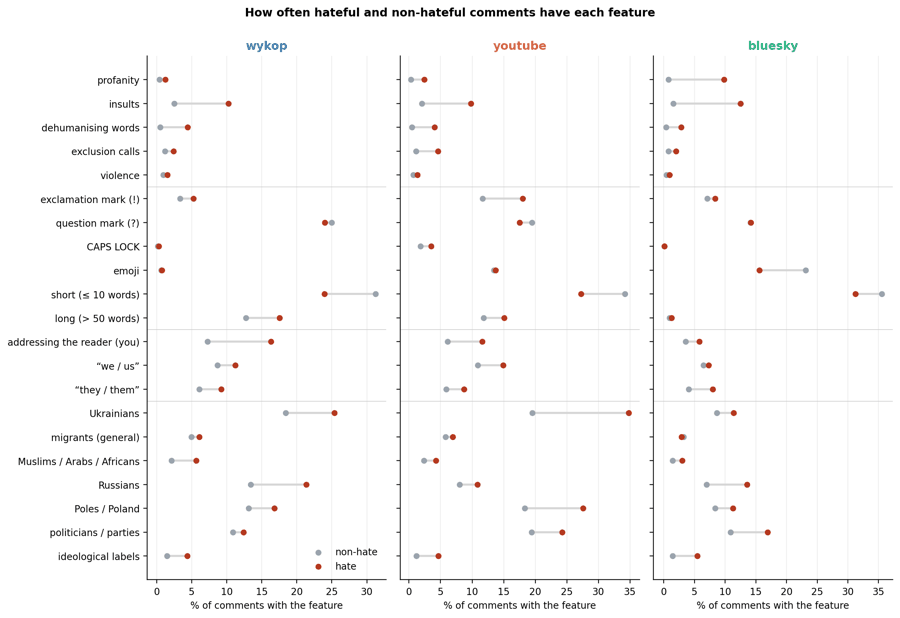

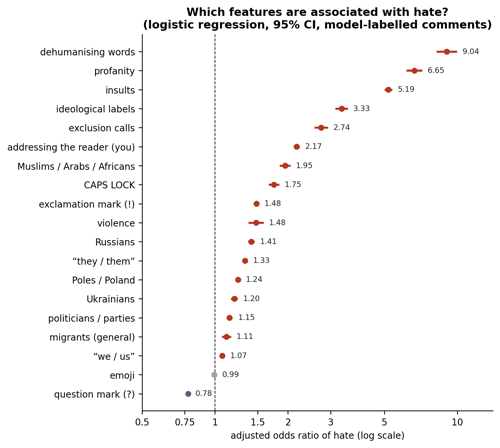

In [14]:
ff.fig_profile()
ff.fig_logit()
show("ha_2_profile")
show("ha_4_logit", 500)